In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

np.random.seed(42)
n_tx = 1000

payment_methods = ['Credit Card', 'Debit Card', 'PayPal', 'Bank Transfer', 'Crypto']
statuses = ['Successful', 'Failed', 'Refunded']

data = {
    'TransactionID': [f'TXN-{10000+i}' for i in range(n_tx)],
    'CustomerID': [f'CUST-{np.random.randint(100, 300)}' for _ in range(n_tx)],
    'Date': pd.date_range(start='2023-01-01', end='2023-12-31', periods=n_tx),
    'Amount': np.random.exponential(scale=150, size=n_tx).round(2) + 10,
    'PaymentMethod': np.random.choice(payment_methods, size=n_tx, p=[0.4, 0.25, 0.2, 0.1, 0.05]),
    'Status': np.random.choice(statuses, size=n_tx, p=[0.82, 0.12, 0.06])
}

df_tx = pd.DataFrame(data)

status_counts = df_tx['Status'].value_counts(normalize=True) * 100

print("=== 📊 وضعیت سلامت تراکنش‌ها (%) ===")
print(status_counts.round(2).to_string())


method_summary = df_tx.groupby('PaymentMethod').agg(
    Total_Volume=('Amount', 'sum'),
    Avg_Amount=('Amount', 'mean'),
    Transaction_Count=('TransactionID', 'count')
).reset_index().sort_values(by='Total_Volume', ascending=False)

print("\n=== 💳 ارزش مالی به تفکیک روش پرداخت ===")
print(method_summary.to_string(index=False))

=== 📊 وضعیت سلامت تراکنش‌ها (%) ===
Status
Successful    81.2
Failed        12.9
Refunded       5.9

=== 💳 ارزش مالی به تفکیک روش پرداخت ===
PaymentMethod  Total_Volume  Avg_Amount  Transaction_Count
  Credit Card      67469.88  165.773661                407
   Debit Card      38280.81  156.888566                244
       PayPal      34692.01  166.788510                208
Bank Transfer      13491.07  146.642065                 92
       Crypto       7144.35  145.803061                 49


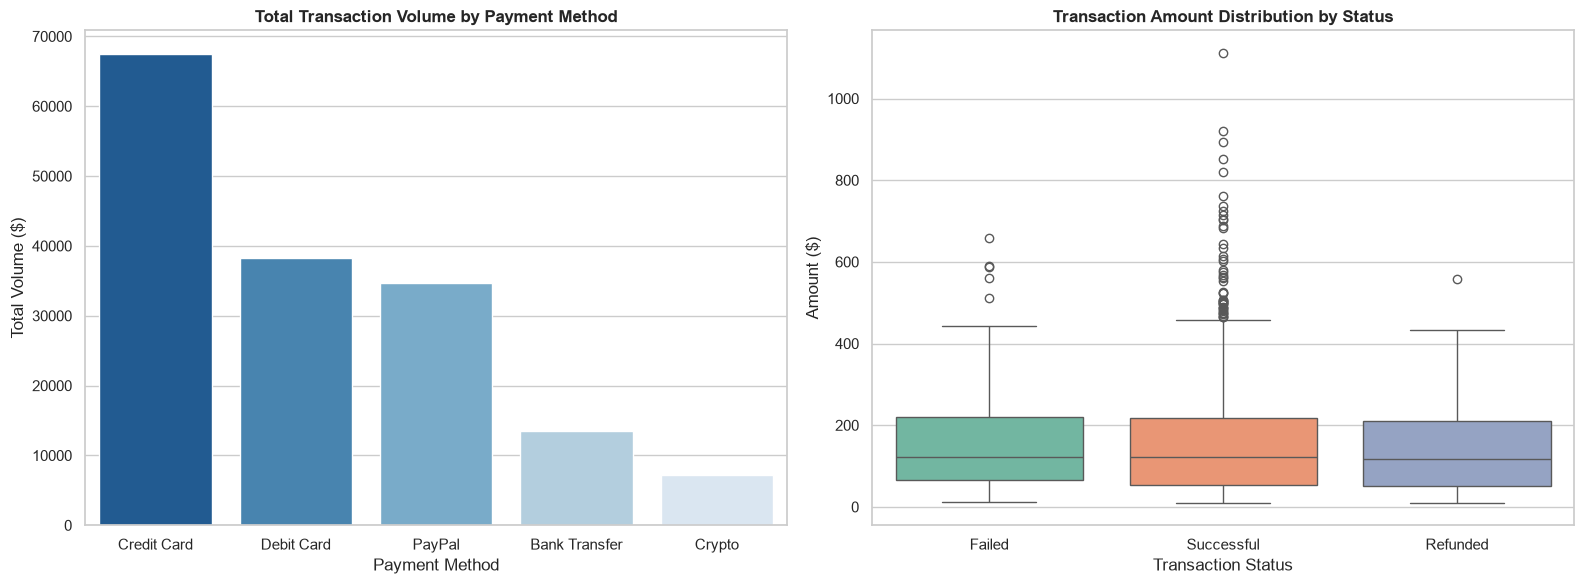

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))


sns.barplot(
    ax=axes[0], 
    data=method_summary, 
    x='PaymentMethod', 
    y='Total_Volume', 
    hue='PaymentMethod', 
    palette='Blues_r', 
    legend=False
)
axes[0].set_title('Total Transaction Volume by Payment Method', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Payment Method')
axes[0].set_ylabel('Total Volume ($)')


sns.boxplot(
    ax=axes[1], 
    data=df_tx, 
    x='Status', 
    y='Amount', 
    hue='Status', 
    palette='Set2', 
    legend=False
)
axes[1].set_title('Transaction Amount Distribution by Status', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Transaction Status')
axes[1].set_ylabel('Amount ($)')

plt.tight_layout()
plt.show()